In [5]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import yaml

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 1000)
sns.set_theme(style="whitegrid")

with open("../../config/config.yaml", "r", encoding="utf-8") as f:
    config = yaml.safe_load(f)

RAW_DIR = Path("../../") / config["data_ingestion"]["paths"]["raw_dir"]
TARGET_CLUB = config["project"]["target_club"]

# Inventory all fetched Parquet files
parquet_files = sorted(RAW_DIR.glob("*.parquet"))
inventory = []
tables = {}

for fp in parquet_files:
    df = pd.read_parquet(fp)
    tables[fp.stem] = df
    inventory.append({
        "table": fp.stem,
        "rows": len(df),
        "cols": df.shape[1],
        "null_cells": int(df.isna().sum().sum()),
        "memory_mb": round(df.memory_usage(deep=True).sum() / 1e6, 2),
    })

display(pd.DataFrame(inventory))


,table,rows,cols,null_cells,memory_mb
0,fbref_player_keeper,333,27,190,0.09
1,fbref_player_misc,5158,21,11266,1.16
2,fbref_player_playing_time,6335,25,17120,1.71
3,fbref_player_shooting,5158,19,4598,1.07
4,fbref_player_standard,5158,25,950,1.35
5,fbref_schedules,3508,17,13351,1.08
6,fbref_team_keeper,192,24,64,0.05
7,fbref_team_misc,192,18,420,0.04
8,fbref_team_playing_time,192,22,36,0.05
9,fbref_team_shooting,192,16,36,0.04


In [13]:
std_df = tables["fbref_player_standard"]
print("Standard Player Columns:\n", std_df.columns.tolist())
print("\nData Types Summary:\n", std_df.dtypes.value_counts())

display(std_df[["league", "season", "team", "player", "nation", "pos", "age", "Playing Time_Min"]].head(10))


Standard Player Columns:
 ['league', 'season', 'team', 'player', 'nation', 'pos', 'age', 'born', 'Playing Time_MP', 'Playing Time_Starts', 'Playing Time_Min', 'Playing Time_90s', 'Performance_Gls', 'Performance_Ast', 'Performance_G+A', 'Performance_G-PK', 'Performance_PK', 'Performance_PKatt', 'Performance_CrdY', 'Performance_CrdR', 'Per 90 Minutes_Gls', 'Per 90 Minutes_Ast', 'Per 90 Minutes_G+A', 'Per 90 Minutes_G-PK', 'Per 90 Minutes_G+A-PK']

Data Types Summary:
 Int64      12
Float64     7
string      6
Name: count, dtype: int64


,league,season,team,player,nation,pos,age,Playing Time_Min
0,ENG-Premier League,2526,Arsenal,Ben White,ENG,DF,27.0,702
1,ENG-Premier League,2526,Arsenal,Bukayo Saka,ENG,"FW,MF",23.0,2222
2,ENG-Premier League,2526,Arsenal,Christian Nørgaard,DEN,MF,31.0,106
3,ENG-Premier League,2526,Arsenal,Cristhian Mosquera,ESP,DF,21.0,994
4,ENG-Premier League,2526,Arsenal,David Raya,ESP,GK,29.0,3330
5,ENG-Premier League,2526,Arsenal,Declan Rice,ENG,MF,26.0,3094
6,ENG-Premier League,2526,Arsenal,Eberechi Eze,ENG,"MF,FW",27.0,1812
7,ENG-Premier League,2526,Arsenal,Ethan Nwaneri,ENG,MF,18.0,171
8,ENG-Premier League,2526,Arsenal,Gabriel Jesus,BRA,FW,28.0,429
9,ENG-Premier League,2526,Arsenal,Gabriel Magalhães,BRA,DF,27.0,2751


In [17]:
schedules = tables["fbref_schedules"]

display(schedules[["league", "home_team"]].query("league == 'GER-Bundesliga'").head(10))

,league,home_team
2134,GER-Bundesliga,Bayern Munich
2135,GER-Bundesliga,Frankfurt
2136,GER-Bundesliga,Freiburg
2137,GER-Bundesliga,Heidenheim
2138,GER-Bundesliga,Leverkusen
2139,GER-Bundesliga,St Pauli
2140,GER-Bundesliga,Union Berlin
2141,GER-Bundesliga,Gladbach
2142,GER-Bundesliga,Mainz 05
2143,GER-Bundesliga,Hamburger SV


In [7]:
for season, grp in std_df.groupby("season"):
    dups = grp[grp.duplicated(subset=["player", "nation", "age"], keep=False)]
    print(f"Season {season}: {len(grp)} total rows | {dups['player'].nunique()} multi-club players ({len(dups)} rows)")

# Preview sample multi-club players in the latest season
latest_season = sorted(std_df["season"].unique())[-1]
latest_std = std_df[std_df["season"] == latest_season]
multi_club = latest_std[latest_std.duplicated(subset=["player"], keep=False)].sort_values("player")
display(multi_club[["season", "league", "team", "player", "pos", "age", "Playing Time_Min"]].head(12))


Season 2526: 2839 total rows | 149 multi-club players (298 rows)
Season 2627: 2319 total rows | 34 multi-club players (68 rows)


,season,league,team,player,pos,age,Playing Time_Min
3827,2627,ITA-Serie A,Fiorentina,Albert Guðmundsson,FW,29.43,70
3950,2627,ITA-Serie A,Lazio,Albert Guðmundsson,"FW,MF",29.43,42
3828,2627,ITA-Serie A,Fiorentina,Alieu Njie,"FW,MF",21.51,668
4154,2627,ITA-Serie A,Torino,Alieu Njie,FW,21.51,21
742,2627,ENG-Premier League,Everton,Beto,FW,28.8,33
3830,2627,ITA-Serie A,Fiorentina,Beto,FW,28.8,203
3023,2627,FRA-Ligue 1,Rennes,Boulaye Dia,FW,30.01,304
3953,2627,ITA-Serie A,Lazio,Boulaye Dia,FW,30.01,157
786,2627,ENG-Premier League,Hull City,Brooke Norton-Cuffy,DF,22.85,173
3877,2627,ITA-Serie A,Genoa,Brooke Norton-Cuffy,MF,22.85,180


/var/folders/5h/hnsbttv172scs60h814dbqbr0000gn/T/ipykernel_63779/2193114377.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=pos_counts.values, y=pos_counts.index, ax=axes[1], palette="viridis")


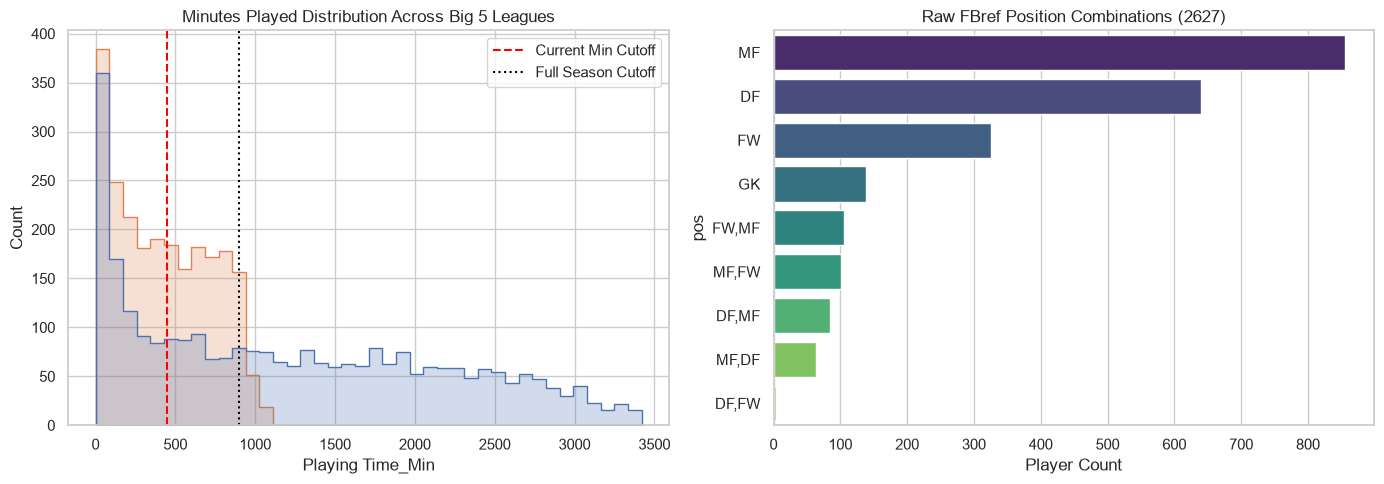

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. Minutes distribution by season
sns.histplot(data=std_df, x="Playing Time_Min", hue="season", bins=40, ax=axes[0], element="step")
axes[0].axvline(config["preprocessing"]["min_minutes_current_season"], color="red", linestyle="--", label="Current Min Cutoff")
axes[0].axvline(config["preprocessing"]["min_minutes_full_season"], color="black", linestyle=":", label="Full Season Cutoff")
axes[0].set_title("Minutes Played Distribution Across Big 5 Leagues")
axes[0].legend()

# 2. Top raw position tags
pos_counts = latest_std["pos"].value_counts().head(12)
sns.barplot(x=pos_counts.values, y=pos_counts.index, ax=axes[1], palette="viridis")
axes[1].set_title(f"Raw FBref Position Combinations ({latest_season})")
axes[1].set_xlabel("Player Count")

plt.tight_layout()
plt.show()


In [9]:
join_keys = ["league", "season", "team", "player"]
base_keys = set(map(tuple, std_df[join_keys].to_numpy()))

player_tables = [k for k in tables if k.startswith("fbref_player_") and k != "fbref_player_standard"]

for name in player_tables:
    df_sub = tables[name]
    sub_keys = set(map(tuple, df_sub[join_keys].to_numpy()))
    missing_from_sub = len(base_keys - sub_keys)
    high_null_cols = df_sub.columns[df_sub.isna().mean() > 0.25].tolist()
    print(f"{name:28s} | Rows: {len(df_sub):5d} | Missing vs Standard: {missing_from_sub:3d} | >25% Null Cols: {high_null_cols}")


fbref_player_keeper          | Rows:   333 | Missing vs Standard: 4825 | >25% Null Cols: ['Penalty Kicks_Save%']
fbref_player_misc            | Rows:  5158 | Missing vs Standard:   0 | >25% Null Cols: ['Performance_PKwon', 'Performance_PKcon']
fbref_player_playing_time    | Rows:  6335 | Missing vs Standard:   0 | >25% Null Cols: ['Starts_Mn/Start', 'Subs_Mn/Sub']
fbref_player_shooting        | Rows:  5158 | Missing vs Standard:   0 | >25% Null Cols: ['Standard_G/SoT']
